# Boids

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.patches as patches
mpl.rcParams['mathtext.fontset'] = 'stix'
mpl.rcParams['font.family'] = 'STIXGeneral'
mpl.rcParams['font.size'] = 16
plt.rcParams["legend.fontsize"] = 12

In [2]:
N = 12
dt = 0.033 #r.TIME_STEP
colors_robots = ['black', 'purple', 'blue', 'cyan', 'green', 'orange', 'red','brown', 'pink', 'lime', 'gray', 'saddlebrown']

In [3]:
def E_d(t,x,adjacency_mat,distance_mat):
    # x.shape = (3,N,tf)
    error_d = 0
    edges_num = 0
    for i in range(N):
        for j in range(i+1,N):
            if adjacency_mat[i,j] == 1:
                error_d += (np.linalg.norm(x[:2,i,t]-x[:2,j,t]) - distance_mat[i,j]) **2
                edges_num += 1
    error_d = np.sqrt(error_d/edges_num)
    return error_d

In [4]:
def E_sim(t,x_sim,x_real):
    # x.shape = (3,N,tf)
    error_sim = 0
    for i in range(N):
        error_sim += (np.linalg.norm(x_real[:2,i,t] - x_sim[:2,i,t])) **2
    return error_sim

In [72]:
# Velocity alignment measure
def E_v(t,x):
    v = (x[:2,:,t+1]-x[:2,:,t])/dt
    v_norm = np.linalg.norm(v,axis=0)
    v_theta = np.arctan2(v[1,:],v[0,:])
    return np.array([np.var(v_norm),np.var(v_theta)])

## Global knowledge

### Simulation

In [31]:
boids_sim = np.load('../boids_last.npy')
boids_centers_sim = np.load('../boids_centers_last.npy')
print(boids_sim.shape)

(3, 12, 2500)


In [64]:
E_v(200,boids_sim)

array([4.70343216e-04, 1.31618210e+00])

(5, 2500)


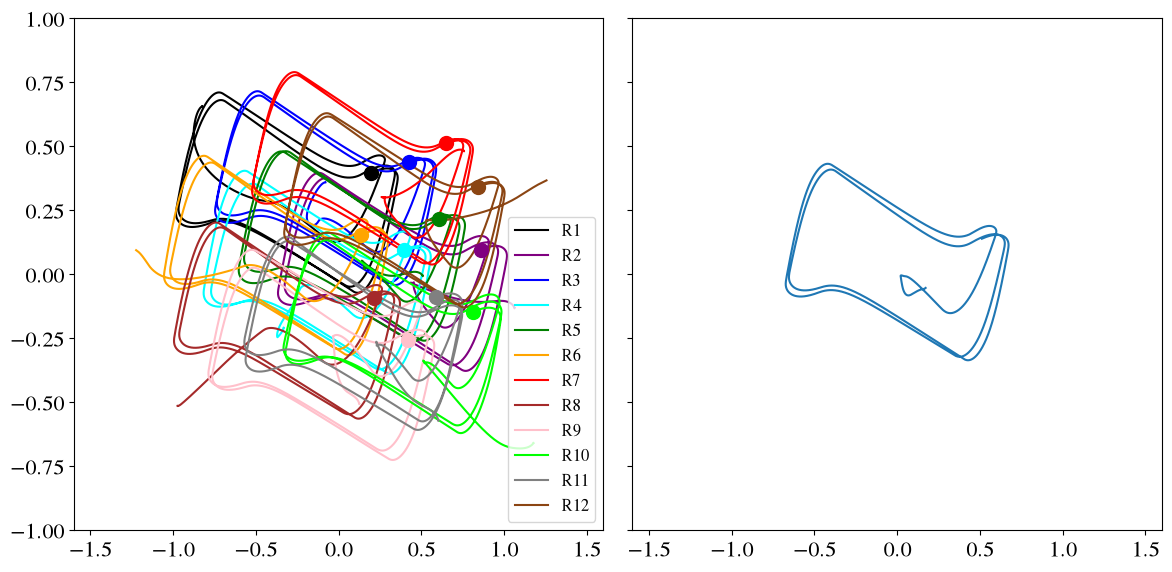

In [6]:
fig, (ax, ax2)= plt.subplots(1,2, figsize=(12,6),layout='tight',sharey=True)
ax.set_xlim(-1.6,1.6)
ax.set_ylim(-1,1)
for i in range(boids_sim.shape[1]):
    ax.plot(boids_sim[0,i,:],boids_sim[1,i,:], label=f'R{i+1}', color=colors_robots[i],zorder=1)
    ax.scatter(boids_sim[0,i,-1],boids_sim[1,i,-1], s=100, color=colors_robots[i],zorder=2)
ax.legend()

print(boids_centers_sim.shape)
ax2.set_xlim(-1.6,1.6)
ax2.set_ylim(-1,1)
ax2.plot(boids_centers_sim[3,:],boids_centers_sim[4,:])
#plt.savefig('../results/boids_sim_trajectories.png',dpi=200, bbox_inches='tight')

(2499, 2)


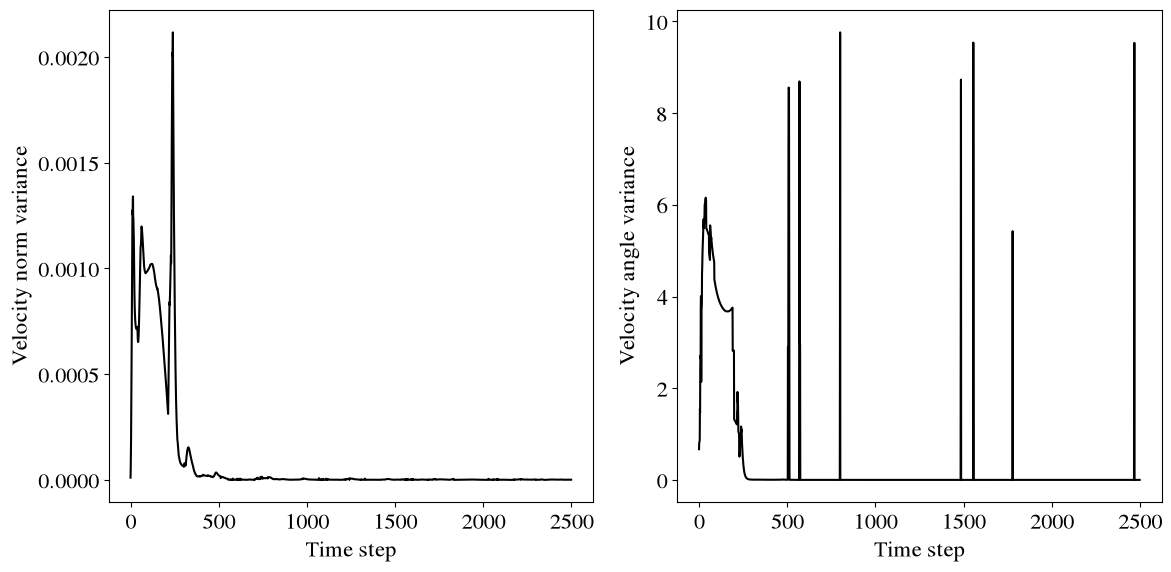

In [77]:
E_v_boids_sim = np.array([E_v(t,boids_sim) for t in range(boids_sim.shape[2]-1)])
print(E_v_boids_sim.shape)

fig, (ax,ax2) = plt.subplots(1,2, figsize=(12,6), layout='tight')
ax.set_xlabel('Time step')
ax.set_ylabel('Velocity norm variance')
ax.plot(E_v_boids_sim[:,0], color='black')

ax2.set_xlabel("Time step")
ax2.set_ylabel("Velocity angle variance")
ax2.plot(E_v_boids_sim[:,1], color='black')
plt.savefig("../results/E_v_boids_sim.png", dpi=300, bbox_inches='tight')

### Hardware

In [5]:
boids_hardware = np.load('../results/boids_hardware.npy')
boids_centers_hardware = np.load('../results/boids_centers_hardware.npy')
print(boids_hardware.shape)
boids_hardware[:,:,0]

(3, 12, 2500)


array([[-0.80404674,  1.07754154, -0.05938078, -0.33971185,  0.50913153,
        -1.22743185,  0.77715337, -0.97767929,  0.10528889,  1.1625098 ,
         0.60713809,  1.2582119 ],
       [ 0.65043472, -0.14580535,  0.35230957, -0.19020842, -0.02596233,
         0.07462124,  0.47771786, -0.53330415, -0.50706133, -0.64664932,
        -0.59150971,  0.34699719],
       [ 1.95899999,  0.792     ,  2.0940001 , -0.80900002,  0.064     ,
        -0.33700001,  0.74900001, -1.58200002, -0.704     , -1.63800001,
        -0.131     , -2.93099999]])

(5, 2500)


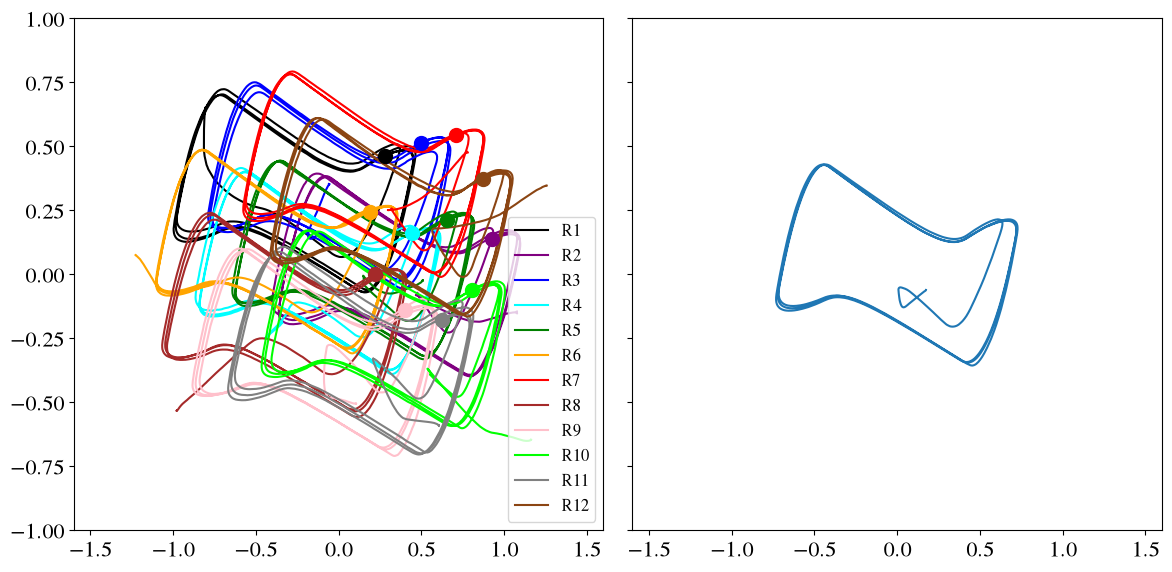

In [8]:
fig, (ax, ax2)= plt.subplots(1,2, figsize=(12,6),layout='tight',sharey=True)
ax.set_xlim(-1.6,1.6)
ax.set_ylim(-1,1)
for i in range(boids_hardware.shape[1]):
    ax.plot(boids_hardware[0,i,:],boids_hardware[1,i,:], label=f'R{i+1}', color=colors_robots[i],zorder=1)
    ax.scatter(boids_hardware[0,i,-1],boids_hardware[1,i,-1], s=100, color=colors_robots[i],zorder=2)
ax.legend()

print(boids_centers_hardware.shape)
ax2.set_xlim(-1.6,1.6)
ax2.set_ylim(-1,1)
ax2.plot(boids_centers_hardware[3,:],boids_centers_hardware[4,:])
#plt.savefig('../results/boids_hardware_trajectories.png',dpi=200, bbox_inches='tight')

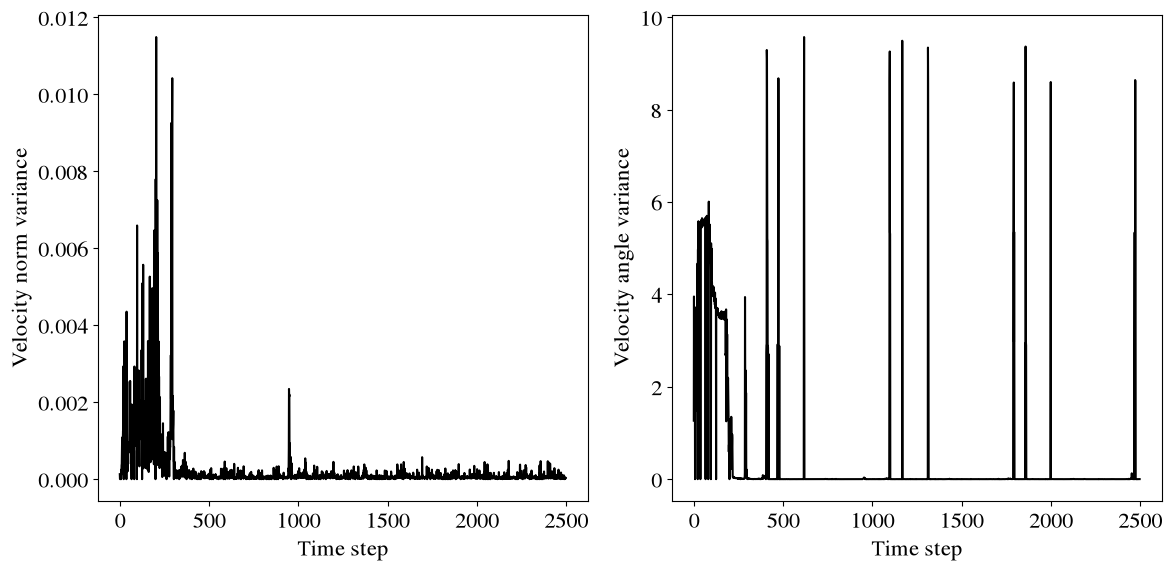

In [78]:
E_v_boids_hardware = np.array([E_v(t,boids_hardware) for t in range(boids_hardware.shape[2]-1)])

fig, (ax,ax2) = plt.subplots(1,2, figsize=(12,6), layout='tight')
ax.set_xlabel('Time step')
ax.set_ylabel('Velocity norm variance')
ax.plot(E_v_boids_hardware[:,0],color='k')

ax2.set_xlabel("Time step")
ax2.set_ylabel("Velocity angle variance")
ax2.plot(E_v_boids_hardware[:,1], color='k')
plt.savefig("../results/E_v_boids_hardware.png", dpi=300, bbox_inches='tight')

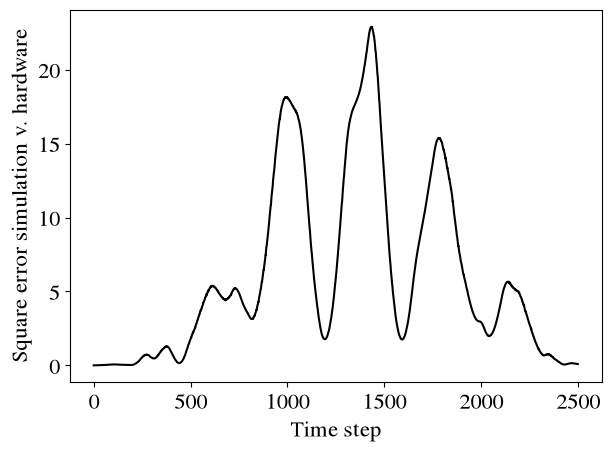

In [9]:
E_sim_boids = [E_sim(t,boids_sim,boids_hardware) for t in range(boids_sim.shape[2])]


fig, ax = plt.subplots(1,1,layout='tight')
ax.set_xlabel('Time step')
ax.set_ylabel('Square error simulation v. hardware')
ax.plot(E_sim_boids, color='black')
#plt.savefig("../results/E_sim_boids.png", dpi=200, bbox_inches='tight')

### Leader-follower

### Simulation

In [10]:
boids_lf_sim = np.load('../boids_leader_follower_last.npy')
boids_lf_centers_sim = np.load('../boids_leader_follower_centers_last.npy')
print(boids_lf_sim.shape)

(3, 12, 2500)


In [46]:
E_v(2000,boids_lf_sim)

np.float64(5.6353324281972545e-05)

(5, 2500)


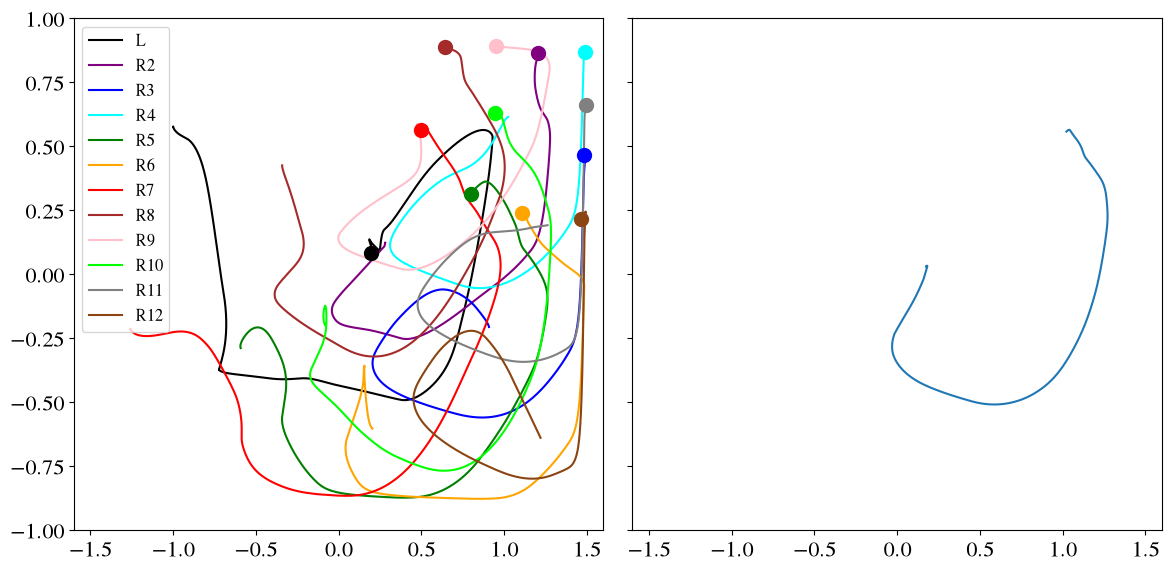

In [12]:
fig, (ax, ax2)= plt.subplots(1,2, figsize=(12,6),layout='tight',sharey=True)
ax.set_xlim(-1.6,1.6)
ax.set_ylim(-1,1)

lf_plots = []
for i in range(boids_lf_sim.shape[1]):
    lf_plot, = ax.plot(boids_lf_sim[0,i,:],boids_lf_sim[1,i,:], label=f'R{i+1}', color=colors_robots[i],zorder=1)
    ax.scatter(boids_lf_sim[0,i,-1],boids_lf_sim[1,i,-1], s=100, color=colors_robots[i],zorder=2)
    lf_plots.append(lf_plot)
lf_plots[0].set_label("L")
ax.legend()

print(boids_lf_centers_sim.shape)
ax2.set_xlim(-1.6,1.6)
ax2.set_ylim(-1,1)
ax2.plot(boids_lf_centers_sim[3,:],boids_lf_centers_sim[4,:])
#plt.savefig('../results/boids_lf_sim_trajectories.png',dpi=200, bbox_inches='tight')

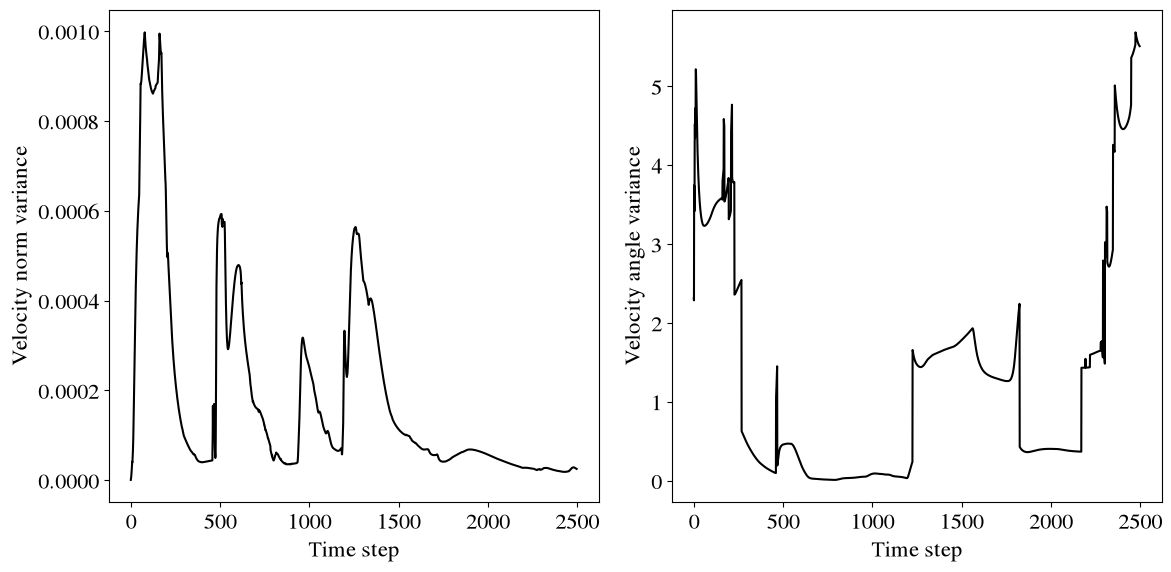

In [79]:
E_v_boids_lf_sim = np.array([E_v(t,boids_lf_sim) for t in range(boids_lf_sim.shape[2]-1)])

fig, (ax,ax2) = plt.subplots(1,2, figsize=(12,6), layout='tight')
ax.set_xlabel('Time step')
ax.set_ylabel('Velocity norm variance')
ax.plot(E_v_boids_lf_sim[:,0], color='black')

ax2.set_xlabel("Time step")
ax2.set_ylabel("Velocity angle variance")
ax2.plot(E_v_boids_lf_sim[:,1], color='black')
plt.savefig("../results/E_v_boids_lf_sim.png", dpi=300, bbox_inches='tight')

### Hardware

In [13]:
boids_lf_hardware = np.load('../results/boids_leader_follower_hardware.npy')
boids_lf_centers_hardware = np.load('../results/boids_leader_follower_centers_hardware.npy')
print(boids_lf_hardware.shape)

(3, 12, 2500)


(5, 2500)


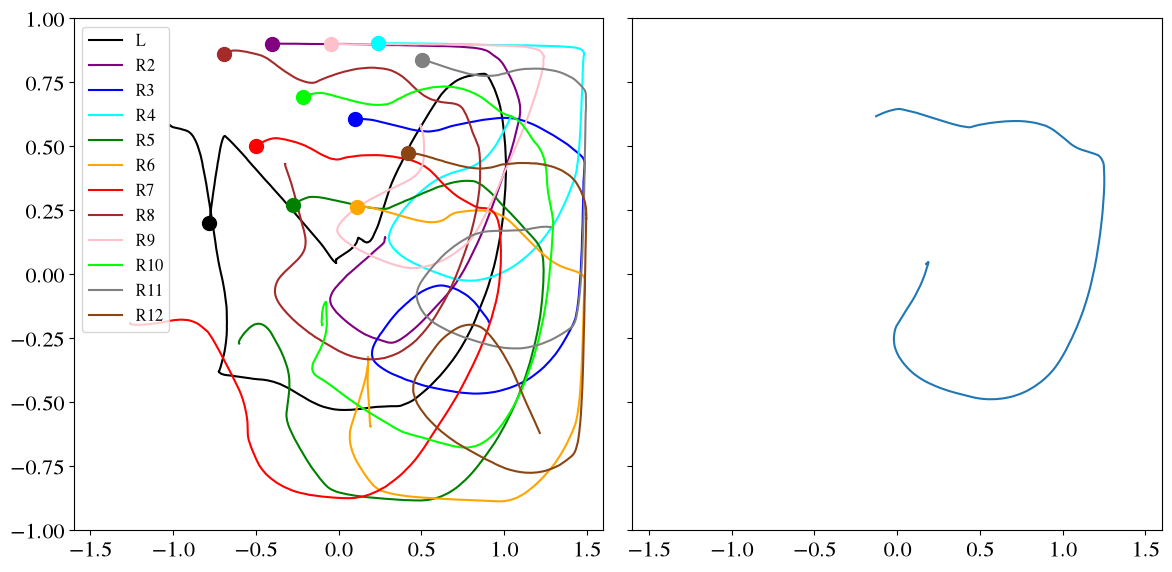

In [15]:
fig, (ax, ax2)= plt.subplots(1,2, figsize=(12,6),layout='tight',sharey=True)
ax.set_xlim(-1.6,1.6)
ax.set_ylim(-1,1)

lf_plots = []
for i in range(boids_lf_hardware.shape[1]):
    lf_plot, = ax.plot(boids_lf_hardware[0,i,:],boids_lf_hardware[1,i,:], label=f'R{i+1}', color=colors_robots[i],zorder=1)
    ax.scatter(boids_lf_hardware[0,i,-1],boids_lf_hardware[1,i,-1], s=100, color=colors_robots[i],zorder=2)
    lf_plots.append(lf_plot)
lf_plots[0].set_label("L")
ax.legend()

print(boids_lf_centers_hardware.shape)
ax2.set_xlim(-1.6,1.6)
ax2.set_ylim(-1,1)
ax2.plot(boids_lf_centers_hardware[3,:],boids_lf_centers_hardware[4,:])
#plt.savefig('../results/boids_lf_hardware_trajectories.png',dpi=200, bbox_inches='tight')

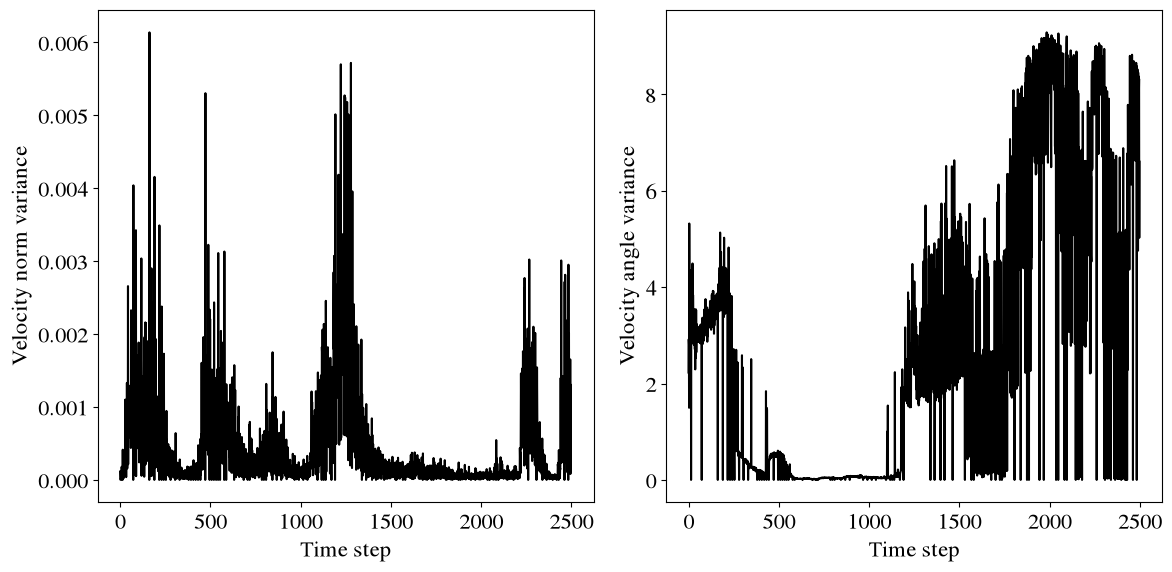

In [80]:
E_v_boids_lf_hardware = np.array([E_v(t,boids_lf_hardware) for t in range(boids_lf_hardware.shape[2]-1)])

fig, (ax,ax2) = plt.subplots(1,2, figsize=(12,6), layout='tight')
ax.set_xlabel('Time step')
ax.set_ylabel('Velocity norm variance')
ax.plot(E_v_boids_lf_hardware[:,0],color='k')

ax2.set_xlabel("Time step")
ax2.set_ylabel("Velocity angle variance")
ax2.plot(E_v_boids_lf_hardware[:,1], color='k')
plt.savefig("../results/E_v_boids_lf_hardware.png", dpi=300, bbox_inches='tight')

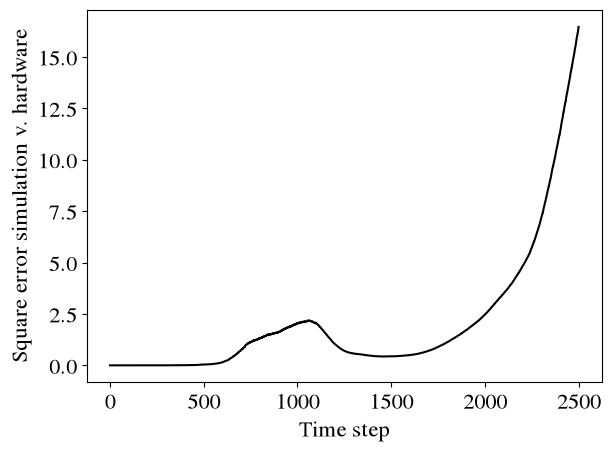

In [16]:
E_sim_boids_lf = [E_sim(t,boids_lf_sim,boids_lf_hardware) for t in range(boids_lf_sim.shape[2])]


fig, ax = plt.subplots(1,1,layout='tight')
ax.set_xlabel('Time step')
ax.set_ylabel('Square error simulation v. hardware')
ax.plot(E_sim_boids_lf, color='black')
#plt.savefig("../results/E_sim_boids_lf.png", dpi=200, bbox_inches='tight')